In [5]:
import pandas as pd
from scipy.io import arff

data, meta = arff.loadarff("../data/bone-marrow.arff")

df = pd.DataFrame(data)

df.head()

,Recipientgender,Stemcellsource,Donorage,Donorage35,IIIV,Gendermatch,DonorABO,RecipientABO,RecipientRh,ABOmatch,...,extcGvHD,CD34kgx10d6,CD3dCD34,CD3dkgx10d8,Rbodymass,ANCrecovery,PLTrecovery,time_to_aGvHD_III_IV,survival_time,survival_status
0,b'1',b'1',22.830137,b'0',b'1',b'0',b'1',b'1',b'1',b'0',...,b'1',7.20,1.338760,5.38,35.0,19.0,51.0,32.0,999.0,0.0
1,b'1',b'0',23.342466,b'0',b'1',b'0',b'-1',b'-1',b'1',b'0',...,b'1',4.50,11.078295,0.41,20.6,16.0,37.0,1000000.0,163.0,1.0
2,b'1',b'0',26.394521,b'0',b'1',b'0',b'-1',b'-1',b'1',b'0',...,b'1',7.94,19.013230,0.42,23.4,23.0,20.0,1000000.0,435.0,1.0
3,b'0',b'0',39.684932,b'1',b'1',b'0',b'1',b'2',b'1',b'1',...,b'?',4.25,29.481647,0.14,50.0,23.0,29.0,19.0,53.0,1.0
4,b'0',b'1',33.358904,b'0',b'0',b'0',b'1',b'2',b'0',b'1',...,b'1',51.85,3.972255,13.05,9.0,14.0,14.0,1000000.0,2043.0,0.0


In [6]:
for column in df.select_dtypes(["object"]).columns:
    df[column] = df[column].str.decode("utf-8")

df.head()
df.shape

(187, 37)

In [7]:
import numpy as np

# Convertir los valores ? y b'?' en valores ausentes
df = df.replace([b'?', '?'], np.nan)

df.isna().sum()

Recipientgender          0
Stemcellsource           0
Donorage                 0
Donorage35               0
IIIV                     0
Gendermatch              0
DonorABO                 0
RecipientABO             1
RecipientRh              2
ABOmatch                 1
CMVstatus               16
DonorCMV                 2
RecipientCMV            14
Disease                  0
Riskgroup                0
Txpostrelapse            0
Diseasegroup             0
HLAmatch                 0
HLAmismatch              0
Antigen                  1
Alel                     1
HLAgrI                   0
Recipientage             0
Recipientage10           0
Recipientageint          0
Relapse                  0
aGvHDIIIIV               0
extcGvHD                31
CD34kgx10d6              0
CD3dCD34                 5
CD3dkgx10d8              5
Rbodymass                2
ANCrecovery              0
PLTrecovery              0
time_to_aGvHD_III_IV     0
survival_time            0
survival_status          0
d

In [11]:
df["survival_status"].value_counts()

survival_status
0.0    102
1.0     85
Name: count, dtype: int64

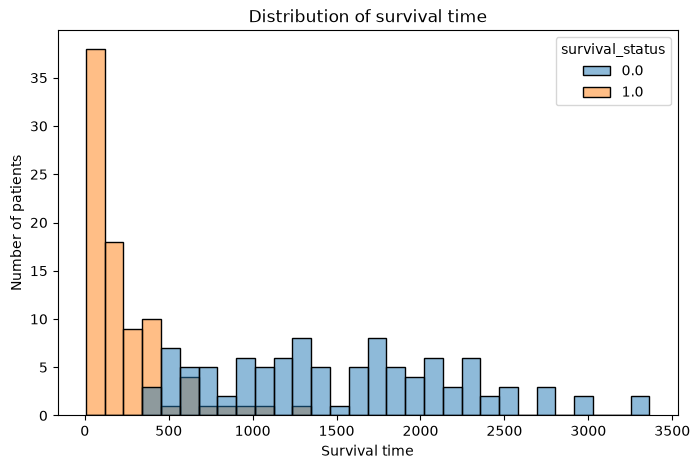

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="survival_time", hue="survival_status", bins=30)
plt.title("Distribution of survival time")
plt.xlabel("Survival time")
plt.ylabel("Number of patients")
plt.show()

In [13]:
special_missing = ["ANCrecovery", "PLTrecovery", "time_to_aGvHD_III_IV"]

df[special_missing] = df[special_missing].replace(1000000, np.nan)

In [14]:
numeric_cols = df.select_dtypes(include=["number"]).columns

correlation = df[numeric_cols].corr()["survival_time"].sort_values()

correlation

survival_status        -0.761462
Rbodymass              -0.145298
Recipientage           -0.137583
ANCrecovery            -0.037152
Donorage                0.005603
CD3dCD34                0.044016
time_to_aGvHD_III_IV    0.060284
CD3dkgx10d8             0.060991
PLTrecovery             0.095127
CD34kgx10d6             0.139313
survival_time           1.000000
Name: survival_time, dtype: float64

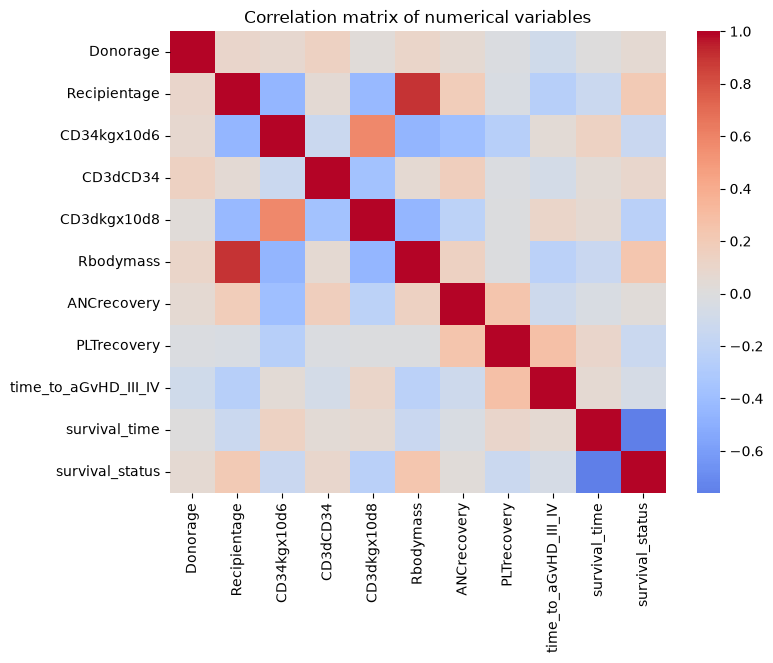

In [15]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df[numeric_cols].corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Correlation matrix of numerical variables")
plt.show()

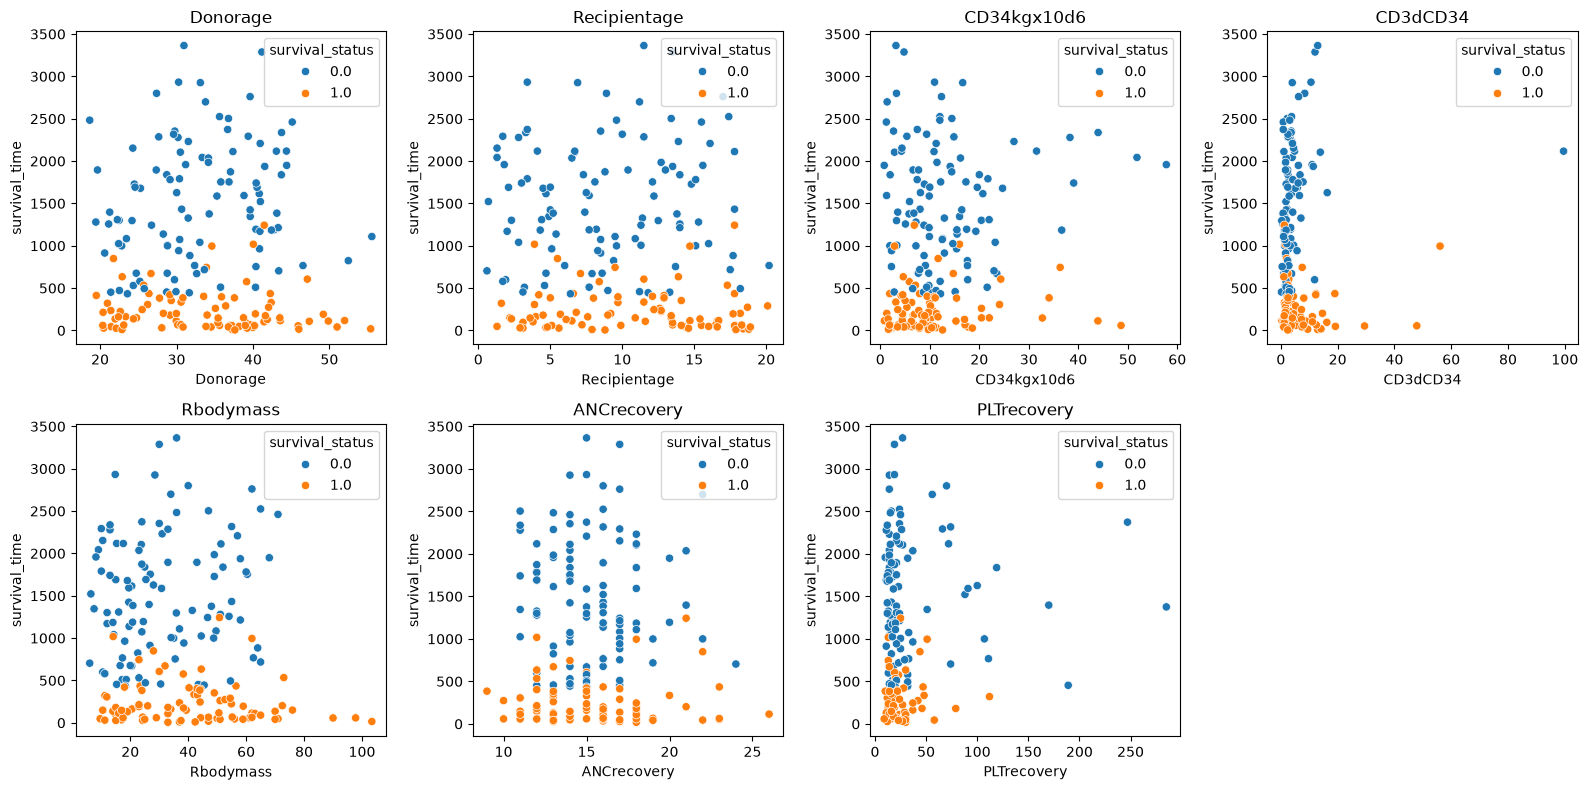

In [16]:
variables = [
    "Donorage",
    "Recipientage",
    "CD34kgx10d6",
    "CD3dCD34",
    "Rbodymass",
    "ANCrecovery",
    "PLTrecovery"
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, variable in enumerate(variables):
    sns.scatterplot(
        data=df,
        x=variable,
        y="survival_time",
        hue="survival_status",
        ax=axes[i]
    )
    axes[i].set_title(variable)

# Ocultar el último espacio vacío
axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

In [17]:
categorical_cols = df.select_dtypes(include=["object"]).columns

for column in categorical_cols:
    print(f"\n{column}")
    print(df[column].value_counts(dropna=False))


Recipientgender
Recipientgender
1    112
0     75
Name: count, dtype: int64

Stemcellsource
Stemcellsource
1    145
0     42
Name: count, dtype: int64

Donorage35
Donorage35
0    104
1     83
Name: count, dtype: int64

IIIV
IIIV
1    112
0     75
Name: count, dtype: int64

Gendermatch
Gendermatch
0    155
1     32
Name: count, dtype: int64

DonorABO
DonorABO
0     73
1     71
-1    28
2     15
Name: count, dtype: int64

RecipientABO
RecipientABO
1      75
-1     50
0      48
2      13
NaN     1
Name: count, dtype: int64

RecipientRh
RecipientRh
1      158
0       27
NaN      2
Name: count, dtype: int64

ABOmatch
ABOmatch
1      134
0       52
NaN      1
Name: count, dtype: int64

CMVstatus
CMVstatus
2      57
0      48
3      39
1      27
NaN    16
Name: count, dtype: int64

DonorCMV
DonorCMV
0      113
1       72
NaN      2
Name: count, dtype: int64

RecipientCMV
RecipientCMV
1      100
0       73
NaN     14
Name: count, dtype: int64

Disease
Disease
ALL             68
chronic       

In [18]:
target_cols = ["survival_time", "survival_status"]

feature_numeric_cols = [
    column for column in numeric_cols
    if column not in target_cols
]

df[feature_numeric_cols].corr()

,Donorage,Recipientage,CD34kgx10d6,CD3dCD34,CD3dkgx10d8,Rbodymass,ANCrecovery,PLTrecovery,time_to_aGvHD_III_IV
Donorage,1.000000,0.094282,0.072530,0.144919,0.023555,0.106707,0.063852,-0.022100,-0.099129
Recipientage,0.094282,1.000000,-0.454347,0.053913,-0.430737,0.897538,0.185860,-0.038947,-0.251803
CD34kgx10d6,0.072530,-0.454347,1.000000,-0.130573,0.583284,-0.465137,-0.394801,-0.257979,0.048462
CD3dCD34,0.144919,0.053913,-0.130573,1.000000,-0.370918,0.061390,0.173974,-0.019445,-0.074732
CD3dkgx10d8,0.023555,-0.430737,0.583284,-0.370918,1.000000,-0.453562,-0.219070,-0.011732,0.112254
Rbodymass,0.106707,0.897538,-0.465137,0.061390,-0.453562,1.000000,0.143401,-0.015926,-0.230696
ANCrecovery,0.063852,0.185860,-0.394801,0.173974,-0.219070,0.143401,1.000000,0.245308,-0.114267
PLTrecovery,-0.022100,-0.038947,-0.257979,-0.019445,-0.011732,-0.015926,0.245308,1.000000,0.276254
time_to_aGvHD_III_IV,-0.099129,-0.251803,0.048462,-0.074732,0.112254,-0.230696,-0.114267,0.276254,1.000000


In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Variables que NO se utilizarán para crear los clusters
target_columns = ["survival_time", "survival_status"]

# Copia de las variables predictoras
X = df.drop(columns=target_columns).copy()

# Convertir variables categóricas a variables dummy
X = pd.get_dummies(X, drop_first=False)

# Convertir todo a formato numérico
X = X.astype(float)

# Sustituir infinitos por valores ausentes
X = X.replace([np.inf, -np.inf], np.nan)

# Imputar valores ausentes con la mediana de cada variable
X = X.fillna(X.median())

# Comprobar que no quedan valores ausentes
print("Shape after encoding:", X.shape)
print("Missing values:", X.isna().sum().sum())

Shape after encoding: (187, 83)
Missing values: 0


In [20]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [21]:
#Apply PCA
pca = PCA(n_components=0.90)

X_pca = pca.fit_transform(X_scaled)

print("Original number of features:", X_scaled.shape[1])
print("Number of principal components:", X_pca.shape[1])
print("Explained variance:", pca.explained_variance_ratio_.sum())

Original number of features: 83
Number of principal components: 29
Explained variance: 0.9012221355644832


### CLUSTERING

In [22]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

k_values = range(2, 7)
inertias = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(X_pca)
    
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_pca, labels))

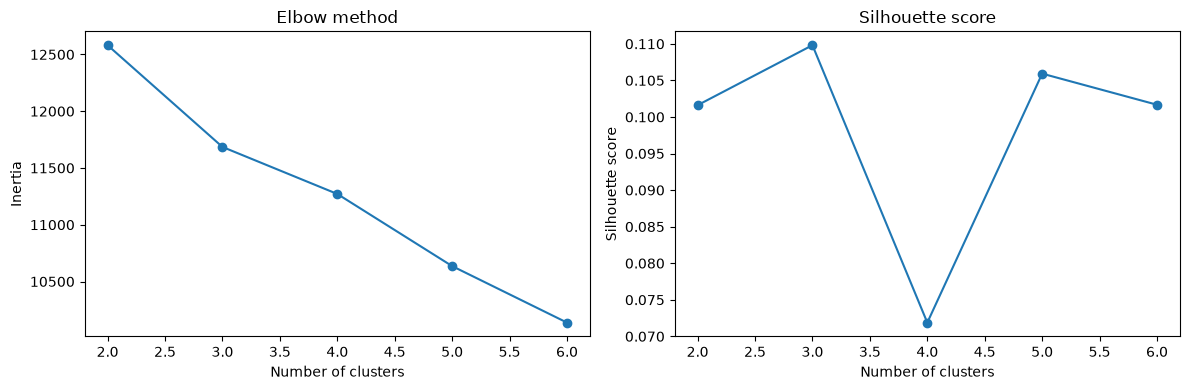

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_values, inertias, marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_values, silhouette_scores, marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.show()

In [24]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_pca)

df["cluster"] = cluster_labels

In [25]:
df["cluster"].value_counts().sort_index()

cluster
0    28
1    94
2    65
Name: count, dtype: int64

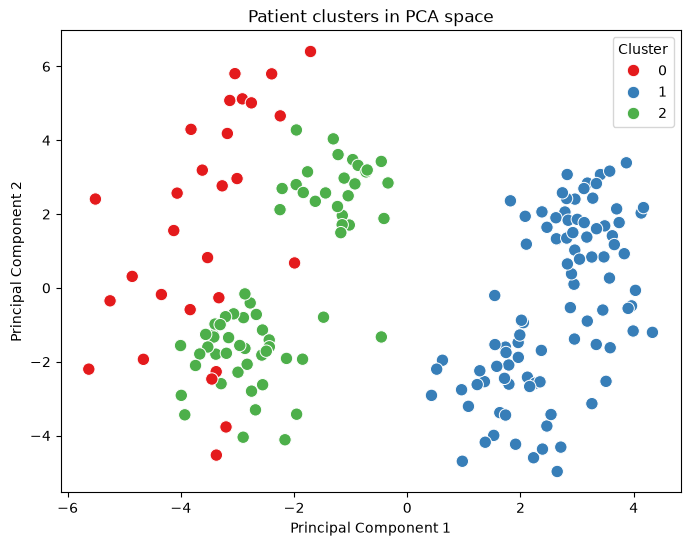

In [26]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df["cluster"],
    palette="Set1",
    s=80
)

plt.title("Patient clusters in PCA space")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()

In [27]:
df.groupby("cluster")[
    [
        "survival_time",
        "survival_status",
        "Donorage",
        "Recipientage",
        "Rbodymass"
    ]
].mean()

,survival_time,survival_status,Donorage,Recipientage,Rbodymass
cluster,,,,,
0,1097.928571,0.464286,35.897652,10.382143,37.458929
1,903.042553,0.436170,32.389158,10.374468,37.090957
2,921.800000,0.476923,33.993256,9.096923,33.139683


### Kaplan-Meier

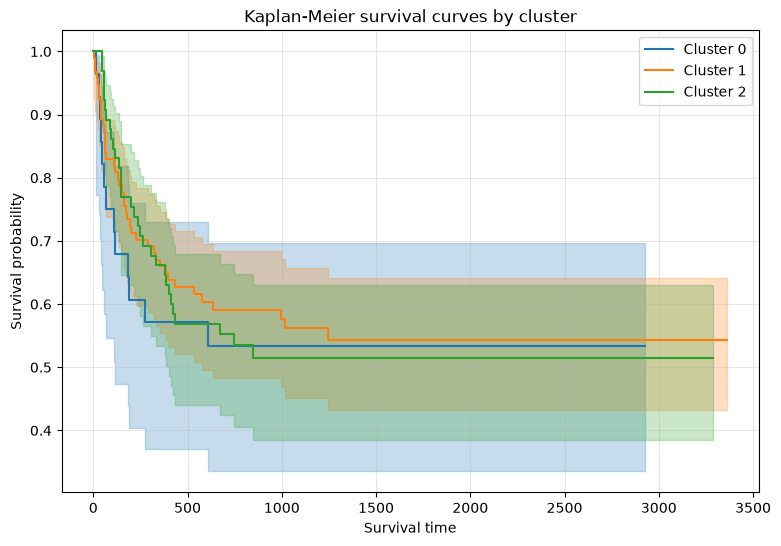

In [28]:
from lifelines import KaplanMeierFitter

kmf = KaplanMeierFitter()

plt.figure(figsize=(9, 6))

for cluster in sorted(df["cluster"].unique()):
    mask = df["cluster"] == cluster
    
    kmf.fit(
        durations=df.loc[mask, "survival_time"],
        event_observed=df.loc[mask, "survival_status"],
        label=f"Cluster {cluster}"
    )
    
    kmf.plot_survival_function()

plt.title("Kaplan-Meier survival curves by cluster")
plt.xlabel("Survival time")
plt.ylabel("Survival probability")
plt.grid(alpha=0.3)
plt.show()

In [29]:
for cluster in sorted(df["cluster"].unique()):
    mask = df["cluster"] == cluster
    
    kmf.fit(
        durations=df.loc[mask, "survival_time"],
        event_observed=df.loc[mask, "survival_status"],
        label=f"Cluster {cluster}"
    )
    
    print(
        f"Cluster {cluster}: "
        f"median survival = {kmf.median_survival_time_}"
    )

Cluster 0: median survival = inf
Cluster 1: median survival = inf
Cluster 2: median survival = inf


In [30]:
from lifelines.statistics import multivariate_logrank_test

results = multivariate_logrank_test(
    event_durations=df["survival_time"],
    groups=df["cluster"],
    event_observed=df["survival_status"]
)

results.print_summary()

In [33]:
from lifelines import CoxPHFitter

cox_data = df[[
    "survival_time",
    "survival_status",
    "cluster"
]].copy()

# Convertir el cluster en variable categórica
cox_data = pd.get_dummies(
    cox_data,
    columns=["cluster"],
    drop_first=True,
    dtype=float
)

cox = CoxPHFitter()

cox.fit(
    cox_data,
    duration_col="survival_time",
    event_col="survival_status"
)

cox.print_summary()

<lifelines.CoxPHFitter: fitted with 187 total observations, 102 right-censored observations>
             duration col = 'survival_time'
                event col = 'survival_status'
      baseline estimation = breslow
   number of observations = 187
number of events observed = 85
   partial log-likelihood = -419.64
         time fit was run = 2026-10-18 17:13:53 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
cluster_1 -0.14      0.87      0.32           -0.77            0.48                0.46                1.62
cluster_2 -0.08      0.92      0.33           -0.73            0.57                0.48                1.76

           cmp to     z    p  -log2(p)
covariate                             
cluster_1    0.00 -0.45 0.65      0.62
cluster_2    0.00 -0.25 0.81      0.31
---
Concordance = 0.52
Partial AIC = 843.28
log-likelihood ratio test = 0.22 on 2 df
-log2(p) of ll-ratio test = 0.16

In [34]:
cox_features = [
    "Donorage",
    "Recipientage",
    "CD34kgx10d6",
    "CD3dCD34",
    "CD3dkgx10d8",
    "ANCrecovery",
    "PLTrecovery",
    "Riskgroup",
    "Relapse",
    "aGvHDIIIIV"
]

cox_data_features = df[
    ["survival_time", "survival_status"] + cox_features
].copy()

# Convertir variables categóricas
cox_data_features = pd.get_dummies(
    cox_data_features,
    columns=["Riskgroup", "Relapse", "aGvHDIIIIV"],
    drop_first=True,
    dtype=float
)

# Imputar valores ausentes
predictor_columns = [
    column for column in cox_data_features.columns
    if column not in ["survival_time", "survival_status"]
]

cox_data_features[predictor_columns] = (
    cox_data_features[predictor_columns]
    .fillna(cox_data_features[predictor_columns].median())
)

In [35]:
cox_features_model = CoxPHFitter()

cox_features_model.fit(
    cox_data_features,
    duration_col="survival_time",
    event_col="survival_status"
)

cox_features_model.print_summary()

<lifelines.CoxPHFitter: fitted with 187 total observations, 102 right-censored observations>
             duration col = 'survival_time'
                event col = 'survival_status'
      baseline estimation = breslow
   number of observations = 187
number of events observed = 85
   partial log-likelihood = -400.31
         time fit was run = 2026-10-18 17:14:32 UTC

---
              coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                     
Donorage      0.02      1.02      0.01           -0.01            0.04                0.99                1.04
Recipientage  0.05      1.05      0.03           -0.00            0.10                1.00                1.10
CD34kgx10d6  -0.01      0.99      0.02           -0.05            0.03                0.96                1.03
CD3dCD34      0.00      1.00      0.01           -0.02            0.02                0.98                1.02
CD3dkgx10d8  -0.09      0.92      0.05           -0.18            0.01                0.84                1.01
ANCrecovery  -0.01      0.99      0.04           -0.09            0.08                0.91                1.08
PLTrecovery  -0.02      0.98      0.01           -0.03           -0.00                0.97                1.00
Riskgroup_1   0.24      1.27      0.23           -0.21            0.70                0.81                2.01
Relapse_1     0.78      2.18      0.26            0.27            1.29                1.31                3.63
aGvHDIIIIV_1 -0.67      0.51      0.25           -1.17           -0.17                0.31                0.84

              cmp to     z      p  -log2(p)
covariate                                  
Donorage        0.00  1.09   0.27      1.86
Recipientage    0.00  1.77   0.08      3.71
CD34kgx10d6     0.00 -0.47   0.64      0.64
CD3dCD34        0.00  0.10   0.92      0.12
CD3dkgx10d8     0.00 -1.85   0.06      3.94
ANCrecovery     0.00 -0.12   0.90      0.14
PLTrecovery     0.00 -2.17   0.03      5.08
Riskgroup_1     0.00  1.04   0.30      1.75
Relapse_1       0.00  3.01 <0.005      8.58
aGvHDIIIIV_1    0.00 -2.65   0.01      6.94
---
Concordance = 0.68
Partial AIC = 820.62
log-likelihood ratio test = 38.88 on 10 df
-log2(p) of ll-ratio test = 15.19

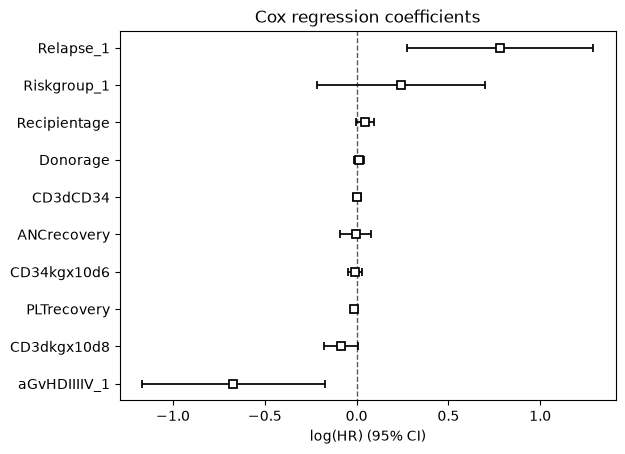

In [36]:
cox_features_model.plot()
plt.title("Cox regression coefficients")
plt.show()


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plo



1. Variable 'Relapse_1' failed the non-proportional test: p-value is <5e-05.

   Advice: with so few unique values (only 2), you can include `strata=['Relapse_1', ...]` in the
call in `.fit`. See documentation in link [E] below.

   Bootstrapping lowess lines. May take a moment...


---
[A]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html
[B]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Bin-variable-and-stratify-on-it
[C]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Introduce-time-varying-covariates
[D]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Modify-the-functional-form
[E]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Stratification



[[<Axes: xlabel='rank-transformed time\n(p=0.1213)'>,
  <Axes: xlabel='km-transformed time\n(p=0.1169)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.8070)'>,
  <Axes: xlabel='km-transformed time\n(p=0.8030)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.1747)'>,
  <Axes: xlabel='km-transformed time\n(p=0.1745)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.8032)'>,
  <Axes: xlabel='km-transformed time\n(p=0.8111)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.4265)'>,
  <Axes: xlabel='km-transformed time\n(p=0.4506)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.6828)'>,
  <Axes: xlabel='km-transformed time\n(p=0.7035)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.5210)'>,
  <Axes: xlabel='km-transformed time\n(p=0.5260)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.8675)'>,
  <Axes: xlabel='km-transformed time\n(p=0.8861)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0000)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0000)'>],
 [<Axes: xlabel='rank-transformed tim

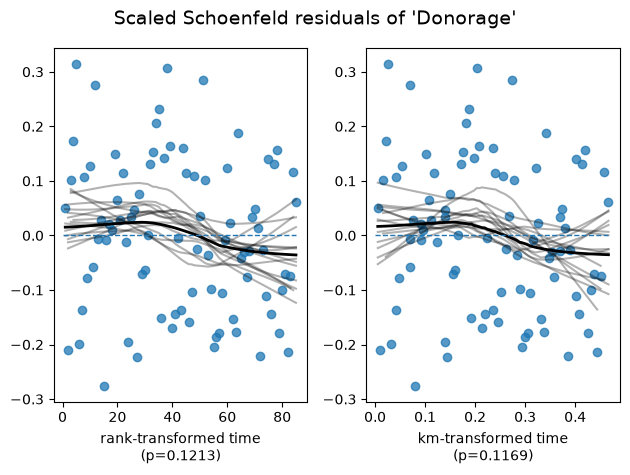

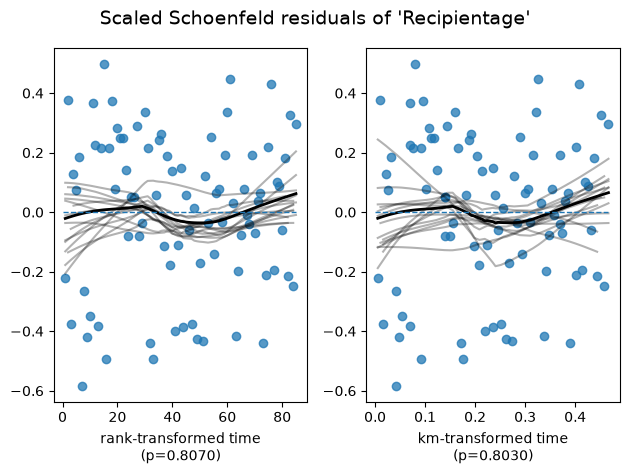

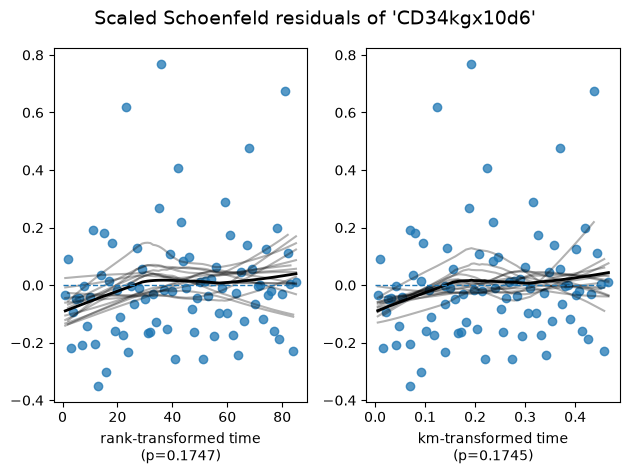

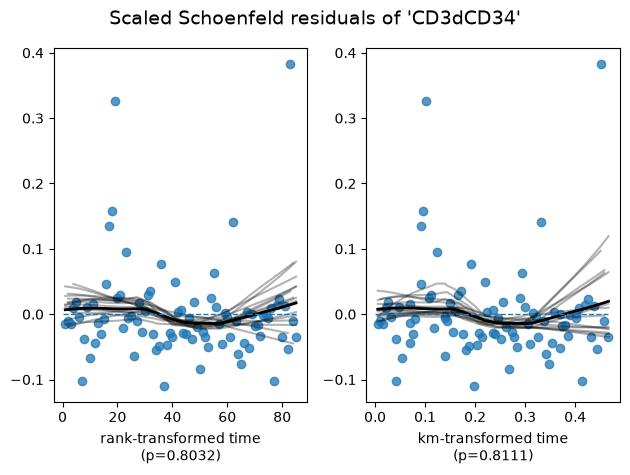

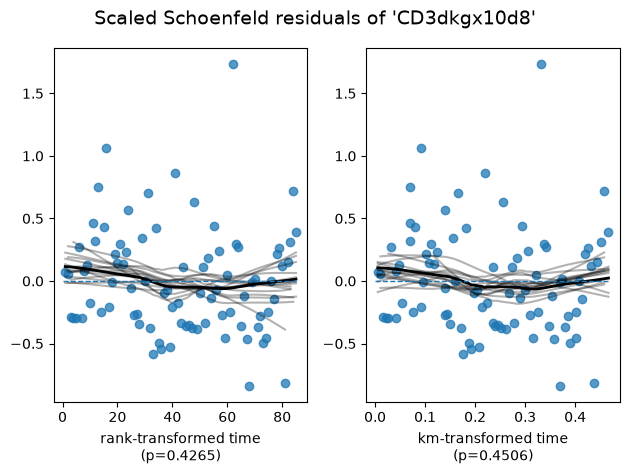

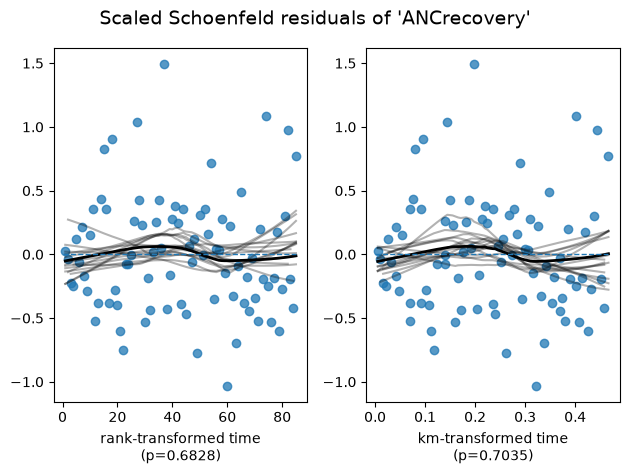

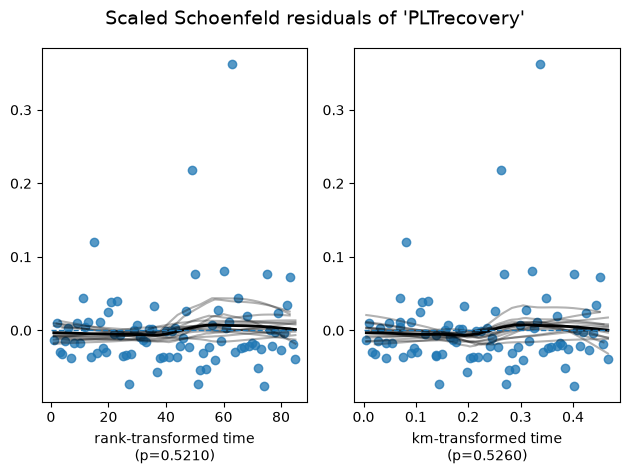

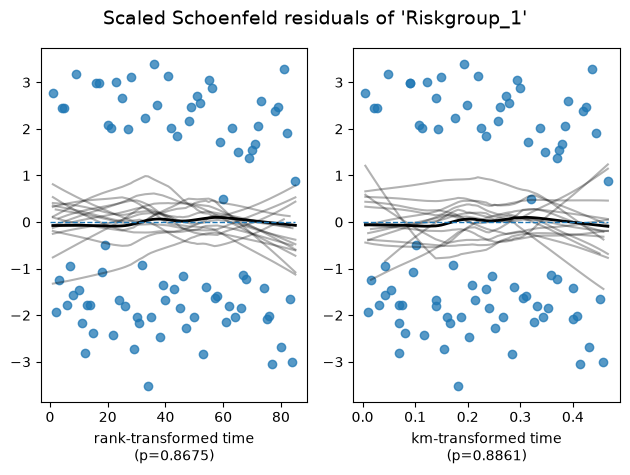

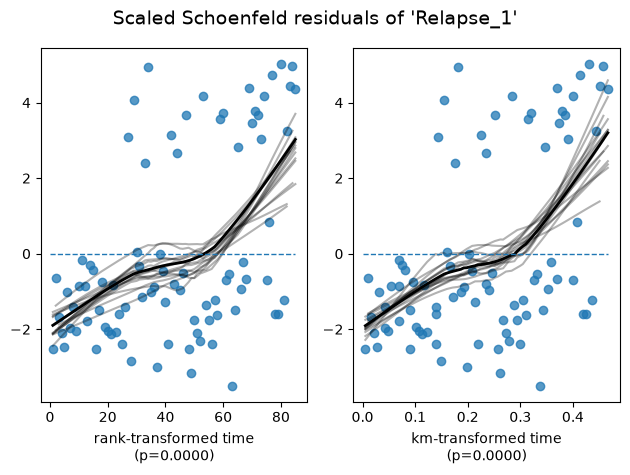

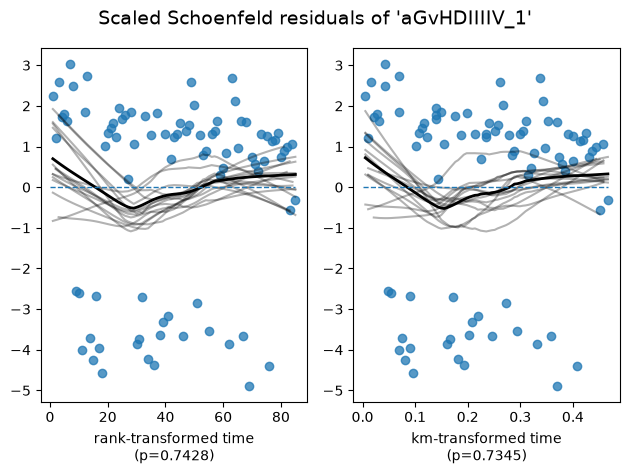

In [38]:
cox_features_model.check_assumptions(
    cox_data_features,
    p_value_threshold=0.05,
    show_plots=True
)

In [40]:
cox_stratified = CoxPHFitter()

cox_stratified.fit(
    cox_data_features,
    duration_col="survival_time",
    event_col="survival_status",
    strata=["Relapse_1"]
)

cox_stratified.print_summary()

<lifelines.CoxPHFitter: fitted with 187 total observations, 102 right-censored observations>
             duration col = 'survival_time'
                event col = 'survival_status'
                   strata = Relapse_1
      baseline estimation = breslow
   number of observations = 187
number of events observed = 85
   partial log-likelihood = -346.04
         time fit was run = 2026-10-18 17:21:28 UTC

---
              coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                     
Donorage      0.01      1.01      0.01           -0.01            0.04                0.99                1.04
Recipientage  0.05      1.05      0.03           -0.00            0.10                1.00                1.10
CD34kgx10d6  -0.00      1.00      0.02           -0.04            0.03                0.96                1.03
CD3dCD34     -0.00      1.00      0.01           -0.02            0.02                0.98                1.02
CD3dkgx10d8  -0.10      0.90      0.05           -0.20           -0.01                0.82                0.99
ANCrecovery  -0.01      0.99      0.04           -0.09            0.07                0.91                1.08
PLTrecovery  -0.01      0.99      0.01           -0.03           -0.00                0.97                1.00
Riskgroup_1   0.37      1.44      0.24           -0.09            0.83                0.91                2.29
aGvHDIIIIV_1 -0.66      0.51      0.26           -1.17           -0.16                0.31                0.85

              cmp to     z    p  -log2(p)
covariate                                
Donorage        0.00  1.02 0.31      1.70
Recipientage    0.00  1.77 0.08      3.70
CD34kgx10d6     0.00 -0.20 0.84      0.25
CD3dCD34        0.00 -0.07 0.94      0.08
CD3dkgx10d8     0.00 -2.16 0.03      5.04
ANCrecovery     0.00 -0.23 0.81      0.30
PLTrecovery     0.00 -2.12 0.03      4.89
Riskgroup_1     0.00  1.56 0.12      3.08
aGvHDIIIIV_1    0.00 -2.59 0.01      6.71
---
Concordance = 0.69
Partial AIC = 710.09
log-likelihood ratio test = 30.77 on 9 df
-log2(p) of ll-ratio test = 11.59

In [41]:
cox_stratified.check_assumptions(
    cox_data_features,
    p_value_threshold=0.05
)

Proportional hazard assumption looks okay.


[]

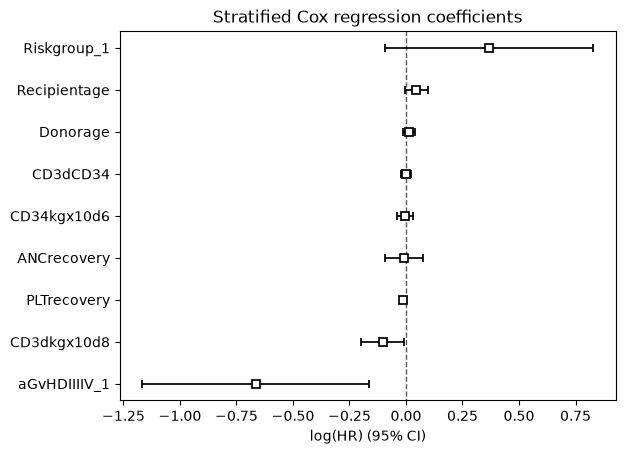

In [47]:
import os

os.makedirs("../figures", exist_ok=True)

cox_stratified.plot()
plt.title("Stratified Cox regression coefficients")

plt.savefig(
    "../figures/cox_coefficients.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()